# Смотрим на MNIST

### Зависимости

torch, numpy, matplotlib, а также SEED = 42, батч 256, Adam с lr = 0.001 и 16 эпох.

### Скачиванием датасет

In [78]:
from urllib.request import urlretrieve

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
filename = "mnist.npz"
urlretrieve(url, filename)

('mnist.npz', <http.client.HTTPMessage at 0x2b9ae24fe50>)

### Выведем пример изображений из датасета

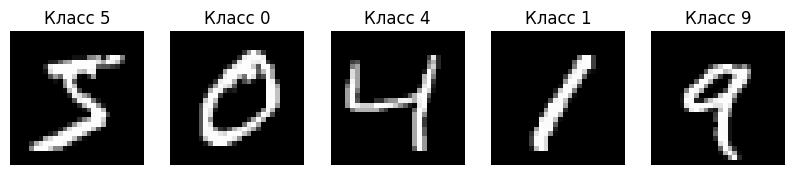

In [79]:
import numpy as np
import matplotlib.pyplot as plt


with np.load(filename) as data:
    images = data["x_train"]
    labels = data["y_train"]

# Показываем предварительные цифры
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Класс {labels[i]}")
    ax.axis("off")

plt.show()

### Разделяем выборку

In [80]:
SEED = 42
VAL_SIZE = 6_000

rng = np.random.default_rng(SEED)
indeces = rng.permutation(len(images))

val_idx = indeces[:VAL_SIZE]
train_idx = indeces[VAL_SIZE:]

x_train, y_train = images[train_idx], labels[train_idx]
x_val, y_val = images[val_idx], labels[val_idx]

print(x_train.shape, y_train.shape)
print(x_val.shape, y_val.shape)

(54000, 28, 28) (54000,)
(6000, 28, 28) (6000,)


### Подготовим одну картинку для PyTorch

In [81]:
import torch


image = torch.from_numpy(x_train[0])
print(image.shape, image.dtype)
print(image.min().item(), image.max().item())

torch.Size([28, 28]) torch.uint8
0 255


### Масштабируем картинку

In [82]:
image_scaled = image.float() / 255
print(image_scaled.dtype)
print(image_scaled.min().item(), image_scaled.max().item())

torch.float32
0.0 1.0


Проворачиваем эту операцию со всей train выборкой

In [83]:
train_images = torch.from_numpy(x_train).float() / 255
val_images = torch.from_numpy(x_val).float() / 255

train_labels = torch.from_numpy(y_train).long()
val_labels = torch.from_numpy(y_val).long()

print(train_labels.shape, train_labels.dtype)
print(val_labels.shape, val_labels.dtype)

torch.Size([54000]) torch.int64
torch.Size([6000]) torch.int64


### Собираем базовую модель

In [84]:
from torch import nn
from copy import deepcopy


torch.manual_seed(SEED)

# Выполняем слои сверху вниз
model = nn.Sequential(
    nn.Flatten(),               # Разворачиваем картинку в ряд чисел
    nn.Linear(28 * 28, 128),    # 28*28 яркости пикселей. Создаем переход из ряда с 28*28 нейронами в 128 нейронов
    nn.ReLU(),                  # Функция активации
    nn.Linear(128, 10)          # Создаем переход из ряда с 128 нейронов в 10 конечных нейронов с весами
)
initial_weights = deepcopy(model.state_dict())
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


### Проверим модель на одной картинке

In [85]:
one_image = train_images[:1]
print(one_image.shape)

torch.Size([1, 28, 28])


In [86]:
logits = model(one_image)
print(logits)

tensor([[ 0.0876, -0.0726,  0.0853, -0.0482, -0.1724,  0.1272,  0.1211, -0.0464,
          0.1793, -0.0238]], grad_fn=<AddmmBackward0>)


### Сделаем summary модели

In [87]:
x = train_images[:1]


# Пропускаем одну картинку через модель для summary
print(f"{'Слой':<60}" + f"{'Форма выхода':<20}" + f"{'Параметры':<20}")
with torch.no_grad():
    for layer in model:
        # Выход текущего слоя
        x = layer(x)
        num_params = sum([p.numel() for p in layer.parameters()])
        print(f"{str(layer):<60}" + f"{str(tuple(x.shape)):<20}" + f"{num_params:<20}")

Слой                                                        Форма выхода        Параметры           
Flatten(start_dim=1, end_dim=-1)                            (1, 784)            0                   
Linear(in_features=784, out_features=128, bias=True)        (1, 128)            100480              
ReLU()                                                      (1, 128)            0                   
Linear(in_features=128, out_features=10, bias=True)         (1, 10)             1290                


In [88]:
print(sum(p.numel() for p in model.parameters()))

101770


### Подготовим для обучения первый батч

In [89]:
from torch.utils.data import TensorDataset, DataLoader


BATCH_SIZE = 256

# Связываем каждую картинку с ее меткой
train_data = TensorDataset(train_images, train_labels)
# Собираем пары картинок и меток в батчи
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,                                     # Перемешиваем пары целиком 
    generator=torch.Generator().manual_seed(SEED)     # Позволяем повторить порядок пееремешивания в след. экспериментах
)

Посмотрим формы картинок и меток

In [90]:
batch_images, batch_labels = next(iter(train_loader))

print(batch_images.shape, batch_labels.shape)

torch.Size([256, 28, 28]) torch.Size([256])


### Посчитаем ошибку модели в первом батче

In [91]:
criterion = nn.CrossEntropyLoss()

logits = model(batch_images)
print(logits.shape)

torch.Size([256, 10])


In [92]:
# Считаем ошибку
loss = criterion(logits, batch_labels)
print(loss.item())

2.2917051315307617


### Теперь сделаем одно обновление весов и снова измерим loss на тех же картинках.

In [93]:
# ? Закомментировано т.к. влияет на обучение при последовательном запуске

# optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# # Очищаем накопленные градиенты
# optimizer.zero_grad()

# loss_before = criterion(model(batch_images), batch_labels)
# # Вычисляем новые градиенты
# loss_before.backward()

# # Обновляем веса по этим градиентам
# optimizer.step()

# with torch.no_grad():
#     loss_after = criterion(model(batch_images), batch_labels)

# print("До обновления:", loss_before.item())
# print("После обновления:", loss_after.item())

### Теперь пройдём одну эпоху

In [94]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
model.train()

for images_batch, labels_batch in train_loader:
    # Очищаем накопленные градиенты
    optimizer.zero_grad()
    # Выполняем предсказания
    logits = model(images_batch)
    # Вычислем функцию потерь
    loss = criterion(logits, labels_batch)
    # Вычисляем новые градиенты
    loss.backward()
    # Устанавливаем веса по новым градиентам
    optimizer.step()
    
print(f"Loss последнего батча: {loss.item()}")
    

Loss последнего батча: 0.2808697521686554


### Создадим загрузчик для оценки

In [95]:
val_data = TensorDataset(val_images, val_labels)

train_eval_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

### Посмотрим предсказания модели

In [96]:
val_batch_images, val_batch_labels = next(iter(val_loader))

with torch.no_grad():
    logits = model(val_batch_images)
    predictions = logits.argmax(dim=1)
    

print("Ответы модели:", predictions[:5].tolist())
print("Правильные ответы:", val_batch_labels[:5].tolist())

Ответы модели: [8, 7, 1, 6, 0]
Правильные ответы: [8, 7, 1, 6, 0]


In [97]:
matches = predictions == val_batch_labels
print(matches[:5])

tensor([True, True, True, True, True])


In [98]:
correct = matches.sum().item()
total = len(val_batch_labels)

print(f"correct: {correct}")
print(f"total: {total}")
print(f"accuracy: {correct / total}")

correct: 234
total: 256
accuracy: 0.9140625


### Создадим функцию для оценки и получения анализа по метрикам

In [99]:
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images_batch, labels_batch in loader:
            logits = model(images_batch)
            loss = criterion(logits, labels_batch)
            n = labels_batch.size(0)
            
            predictions = logits.argmax(dim=1)
            correct += (predictions == labels_batch).sum().item()
            total_loss += loss.item() * n
            total += n
    
    return total_loss / total, correct / total

### Проверим работу функции

In [100]:
train_loss, train_accuracy = evaluate(model, train_eval_loader)
val_loss, val_accuracy = evaluate(model, val_loader)

print(f"Train      | loss = {train_loss:.4f} | accuracy = {train_accuracy:.2%}")
print(f"Validation | loss = {val_loss:.4f} | accuracy = {val_accuracy:.2%}")

Train      | loss = 0.2766 | accuracy = 92.24%
Validation | loss = 0.2956 | accuracy = 91.38%


### Создадим функцию для обучения эпохи

In [101]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    
    for images_batch, labels_batch in loader:
        optimizer.zero_grad()
        logits = model(images_batch)
        loss = criterion(logits, labels_batch)
        loss.backward()
        optimizer.step()

### Обучим 16 эпох и построим графики

In [102]:
from copy import deepcopy


EPOCHS = 16
# Сбрасываем для корректного последовательного запуска
model.load_state_dict(initial_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
history = []
best_score = (-1.0, float("-inf"))

for epoch in range(1, EPOCHS + 1):
    train_one_epoch(model, train_loader, optimizer)
    
    train_loss, train_accuracy = evaluate(model, train_eval_loader)
    val_loss, val_accuracy = evaluate(model, val_loader)
    
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })
    
    score = (val_accuracy, -val_loss)
    
    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_weights = deepcopy(model.state_dict())
        
    print(f"Эпоха {epoch:02d} | train {train_accuracy:.2%} | val {val_accuracy:.2%}")

print(f"Лучшая эпоха: {best_epoch}")

Эпоха 01 | train 92.06% | val 91.37%
Эпоха 02 | train 94.26% | val 93.55%
Эпоха 03 | train 95.49% | val 94.92%
Эпоха 04 | train 96.31% | val 95.70%
Эпоха 05 | train 96.84% | val 96.17%
Эпоха 06 | train 97.40% | val 96.48%
Эпоха 07 | train 97.71% | val 96.67%
Эпоха 08 | train 98.01% | val 96.88%
Эпоха 09 | train 98.21% | val 97.00%
Эпоха 10 | train 98.39% | val 97.00%
Эпоха 11 | train 98.62% | val 97.27%
Эпоха 12 | train 98.93% | val 97.38%
Эпоха 13 | train 99.08% | val 97.28%
Эпоха 14 | train 99.28% | val 97.47%
Эпоха 15 | train 99.30% | val 97.60%
Эпоха 16 | train 99.48% | val 97.53%
Лучшая эпоха: 15


### Графики loss и accuracy

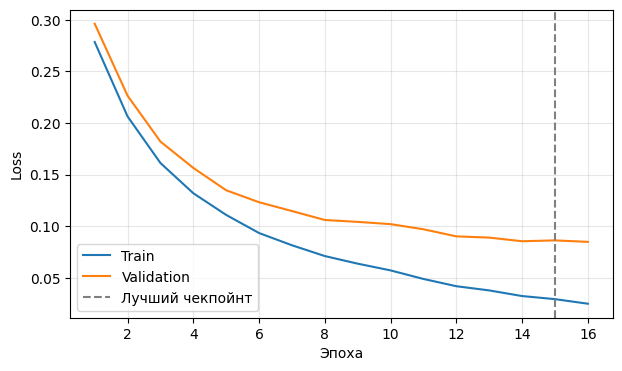

In [103]:
epoch_numbers = [row["epoch"] for row in history]
train_losses = [row["train_loss"] for row in history]
val_losses = [row["val_loss"] for row in history]

plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, train_losses, label="Train")
plt.plot(epoch_numbers, val_losses, label="Validation")
plt.axvline(best_epoch, color="gray", linestyle="--", label="Лучший чекпойнт")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

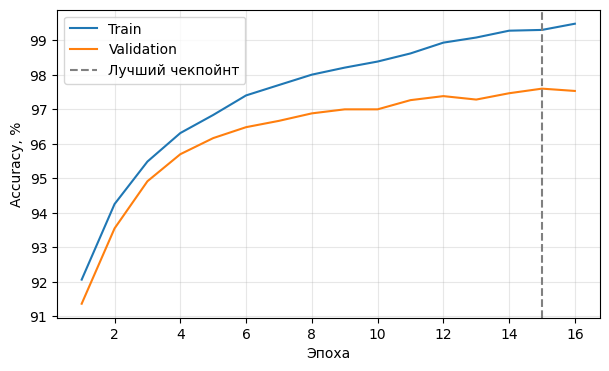

In [104]:
plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, [100 * row["train_accuracy"] for row in history], label="Train")
plt.plot(epoch_numbers, [100 * row["val_accuracy"] for row in history], label="Validation")
plt.axvline(best_epoch, color="gray", linestyle="--", label="Лучший чекпойнт")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy, %")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Вывод исходя из графика
Если train loss продолжает падать, а validation loss в конце стоит на месте или растёт, это признак переобучения. На тренировочных примерах ошибка ещё уменьшается, а на новых картинках улучшение остановилось.

### Сохраним значения нашей исходной модели

In [105]:
baseline_history = history
baseline_best_epoch = best_epoch
baseline_best_weights = best_weights

# Изменение кол-ва скрытых слоев в сети

### Создаздим функцию собирающую сеть нужной глубины

In [106]:
def make_relu_model(hidden_layers: int):
    layers = [nn.Flatten(), nn.Linear(28*28, 128), nn.ReLU()]
    
    # Добавляем скрытые слои
    for _ in range(hidden_layers - 1):
        layers.append(nn.Linear(128, 128))
        layers.append(nn.ReLU())
    
    layers.append(nn.Linear(128, 10))
    return nn.Sequential(*layers)

Проверяем

In [107]:
print(make_relu_model(2))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=10, bias=True)
)


### Вынесем процесс обучения в отдельную функцию

In [108]:
def fit(model, epochs: int = 16):
    loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    history = []
    best_score = (-1.0, float("-inf"))
    
    for epoch in range(1, epochs + 1):
        train_one_epoch(model, loader, optimizer)
        
        train_loss, train_accuracy = evaluate(model, train_eval_loader)
        val_loss, val_accuracy = evaluate(model, val_loader)
        
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
        })
        
        score = (val_accuracy, -val_loss)
        if score > best_score:
            best_score = score
            best_epoch = epoch
            best_weights = deepcopy(model.state_dict())

        print(f"Эпоха {epoch:02d} | val accuracy = {val_accuracy:.2%}")

    return history, best_epoch, best_weights

### Запустим обучение двухслойной модели

In [109]:
torch.manual_seed(SEED)
model_2 = make_relu_model(2)
history_2, best_epoch_2, best_weights_2 = fit(model_2)

Эпоха 01 | val accuracy = 92.33%
Эпоха 02 | val accuracy = 94.50%
Эпоха 03 | val accuracy = 95.45%
Эпоха 04 | val accuracy = 96.47%
Эпоха 05 | val accuracy = 96.87%
Эпоха 06 | val accuracy = 96.70%
Эпоха 07 | val accuracy = 97.03%
Эпоха 08 | val accuracy = 96.88%
Эпоха 09 | val accuracy = 97.23%
Эпоха 10 | val accuracy = 97.07%
Эпоха 11 | val accuracy = 97.28%
Эпоха 12 | val accuracy = 97.70%
Эпоха 13 | val accuracy = 97.42%
Эпоха 14 | val accuracy = 97.62%
Эпоха 15 | val accuracy = 97.65%
Эпоха 16 | val accuracy = 97.52%


In [110]:
print(history_2[best_epoch_2 - 1])

{'epoch': 12, 'train_loss': 0.019987362619903352, 'train_accuracy': 0.9952592592592593, 'val_loss': 0.08815814328193665, 'val_accuracy': 0.977}


### Обучим трехслойную модель

In [111]:
torch.manual_seed(SEED)
model_3 = make_relu_model(3)
history_3, best_epoch_3, best_weights_3 = fit(model_3)

print(history_3[best_epoch_3 - 1])

Эпоха 01 | val accuracy = 92.53%
Эпоха 02 | val accuracy = 94.60%
Эпоха 03 | val accuracy = 95.90%
Эпоха 04 | val accuracy = 96.60%
Эпоха 05 | val accuracy = 97.12%
Эпоха 06 | val accuracy = 96.97%
Эпоха 07 | val accuracy = 97.33%
Эпоха 08 | val accuracy = 97.13%
Эпоха 09 | val accuracy = 97.57%
Эпоха 10 | val accuracy = 97.33%
Эпоха 11 | val accuracy = 97.62%
Эпоха 12 | val accuracy = 97.42%
Эпоха 13 | val accuracy = 97.58%
Эпоха 14 | val accuracy = 97.55%
Эпоха 15 | val accuracy = 97.50%
Эпоха 16 | val accuracy = 97.53%
{'epoch': 11, 'train_loss': 0.019305711422805433, 'train_accuracy': 0.9945925925925926, 'val_loss': 0.09083640476067861, 'val_accuracy': 0.9761666666666666}


In [112]:
print(baseline_history[baseline_best_epoch - 1])

{'epoch': 15, 'train_loss': 0.02927365763319863, 'train_accuracy': 0.9930185185185185, 'val_loss': 0.08621373305718104, 'val_accuracy': 0.976}


### Микровыводы

| Скрытых слоёв |	Лучшая эпоха |	Validation accuracy |	Validation loss |
|:---:|:---:|:---:|:---:|
| 1	| 14	| 97,63%	| 0,0851 |
| 2	| 12	| 97,70%	| 0,0882 |
| 3	| 11	| 97,62%	| 0,0908 |

У однослойной модели ниже loss, но мы заранее выбрали accuracy основным критерием. Два слоя дали 4 дополнительных правильных ответа из 6 000 по сравнению с одним слоем. Это небольшой выигрыш в этом запуске. Добавление третьего слоя точность не улучшило

# Напишем свою активацию

In [113]:
class MyActivation(nn.Module):
    def __init__(self):
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor(0.1))
        
    def forward(self, x):
        positive = x.clamp_min(0)
        negative = x.clamp_max(0)
        return positive + negative * self.alpha

### Проверим свой активатор

In [114]:
torch.manual_seed(SEED)
relu_start = make_relu_model(2)

model_alpha = deepcopy(relu_start)
activation = MyActivation()

model_alpha[2] = activation
model_alpha[4] = activation

print(model_alpha)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): MyActivation()
  (3): Linear(in_features=128, out_features=128, bias=True)
  (4): MyActivation()
  (5): Linear(in_features=128, out_features=10, bias=True)
)


In [115]:
history_alpha, best_epoch_alpha, best_weights_alpha = fit(model_alpha)

print(history_alpha[best_epoch_alpha - 1])
print("Alpha в лучшем чекпойнте:", best_weights_alpha["2.alpha"].item())

Эпоха 01 | val accuracy = 92.07%
Эпоха 02 | val accuracy = 94.47%
Эпоха 03 | val accuracy = 95.52%
Эпоха 04 | val accuracy = 96.53%
Эпоха 05 | val accuracy = 96.98%
Эпоха 06 | val accuracy = 96.85%
Эпоха 07 | val accuracy = 97.02%
Эпоха 08 | val accuracy = 97.25%
Эпоха 09 | val accuracy = 97.23%
Эпоха 10 | val accuracy = 97.33%
Эпоха 11 | val accuracy = 97.63%
Эпоха 12 | val accuracy = 97.60%
Эпоха 13 | val accuracy = 97.72%
Эпоха 14 | val accuracy = 97.80%
Эпоха 15 | val accuracy = 97.50%
Эпоха 16 | val accuracy = 97.60%
{'epoch': 14, 'train_loss': 0.005975377458941053, 'train_accuracy': 0.9990370370370371, 'val_loss': 0.09823353600502015, 'val_accuracy': 0.978}
Alpha в лучшем чекпойнте: -0.7409939169883728


### Вывод
Своя активация дала 97,80% на валидации против 97,70% у двухслойной ReLU. Это 6 дополнительных правильных ответов из 6 000. При этом val_loss вырос с 0,0882 до 0,0982, так что результат зависит от того, какую метрику смотрим. По выбранному критерию accuracy модель с α пока лидирует.

В лучшем чекпойнте на 14-й эпохе α изменился с 0,1 до −0,7410. Теперь отрицательный вход, например −2, даёт положительный выход около 1,48. ReLU на таком входе дала бы 0.

# Два скрытых слоя без активации

In [116]:
model_linear = deepcopy(relu_start)

model_linear[2] = nn.Identity()
model_linear[4] = nn.Identity()

history_linear, best_epoch_linear, best_weights_linear = fit(model_linear)
print(history_linear[best_epoch_linear - 1])

Эпоха 01 | val accuracy = 90.97%
Эпоха 02 | val accuracy = 91.25%
Эпоха 03 | val accuracy = 91.50%
Эпоха 04 | val accuracy = 91.52%
Эпоха 05 | val accuracy = 91.67%
Эпоха 06 | val accuracy = 91.07%
Эпоха 07 | val accuracy = 91.80%
Эпоха 08 | val accuracy = 92.05%
Эпоха 09 | val accuracy = 91.53%
Эпоха 10 | val accuracy = 91.70%
Эпоха 11 | val accuracy = 91.77%
Эпоха 12 | val accuracy = 91.93%
Эпоха 13 | val accuracy = 91.83%
Эпоха 14 | val accuracy = 91.68%
Эпоха 15 | val accuracy = 91.63%
Эпоха 16 | val accuracy = 91.92%
{'epoch': 8, 'train_loss': 0.2444137106515743, 'train_accuracy': 0.9322222222222222, 'val_loss': 0.3016133459011714, 'val_accuracy': 0.9205}


### Микровывод

При одинаковых начальных весах и настройках обучения модель с двумя скрытыми слоями без активаций достигла 92,05% точности на валидации на 8-й эпохе. Такая же модель с ReLU достигла 97,70% на 12-й эпохе.

Разрыв виден и на обучающей выборке — 93,22% без активаций против 99,53% с ReLU. Это согласуется с тем, что модели без нелинейности сложнее подстроиться даже под обучающие данные.

# Общие итоги

### Сравнение двухслойных моделей с ReLU и без активаций

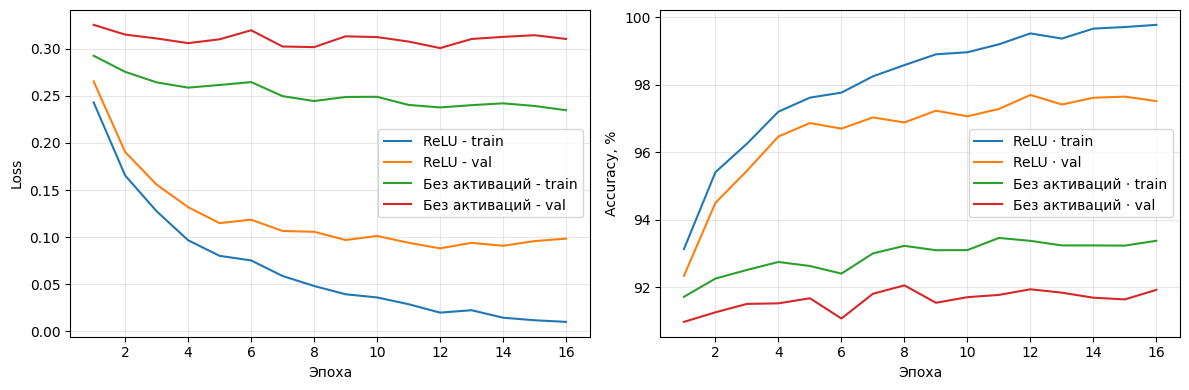

In [117]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

for name, rows in [("ReLU", history_2), ("Без активаций", history_linear)]:
    xs = [row["epoch"] for row in rows]
    
    ax_loss.plot(xs, [row["train_loss"] for row in rows], label=f"{name} - train")
    ax_loss.plot(xs, [row["val_loss"] for row in rows], label=f"{name} - val")
    
    train_acc_percent = [row["train_accuracy"] * 100 for row in rows]
    val_acc_percent = [row["val_accuracy"] * 100 for row in rows]

    ax_acc.plot(xs, train_acc_percent, label=f"{name} · train")
    ax_acc.plot(xs, val_acc_percent, label=f"{name} · val")
    
ax_loss.set(xlabel="Эпоха", ylabel="Loss")
ax_acc.set(xlabel="Эпоха", ylabel="Accuracy, %")

for ax in (ax_loss, ax_acc):
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Сравнение моделей на валидационной выборке

| Скрытых слоёв | Активация | Лучшая эпоха | Validation accuracy | Validation loss | α |
|---:|---|---:|---:|---:|---:|
| 1 | ReLU | 14 | 97,63% | 0,0851 | — |
| 2 | ReLU | 12 | 97,70% | 0,0882 | — |
| 3 | ReLU | 11 | 97,62% | 0,0908 | — |
| 2 | Обучаемая активация | 14 | **97,80%** | 0,0982 | −0,7410 |
| 2 | Без активаций | 8 | 92,05% | 0,3016 | — |

Я выбирал лучший чекпойнт по максимальной точности на валидации. При равной точности я выбирал чекпойнт с меньшим `validation loss`. Среди моделей с ReLU лучший результат дали два скрытых слоя. По сравнению с одним слоем модель правильно распознала ещё 4 картинки из 6 000. Добавление третьего слоя точность не повысило.

Лучший результат среди всех вариантов дала модель с двумя скрытыми слоями и обучаемой активацией. На 14-й эпохе она достигла 97,80% точности на валидации. Общий параметр $\alpha$ для двух скрытых слоёв изменился с 0,1 до −0,7410. Я предполагаю, что активация помогла сохранить сигнал от отрицательных входов, которые ReLU обнуляет. Выигрыш составил 6 правильных ответов из 6 000, а `validation loss` вырос с 0,0882 до 0,0982. Поэтому преимущество по точности относится к этому запуску.

При удалении активаций точность на валидации снизилась с 97,70% до 92,05%. Два последовательных слоя `Linear` со смещениями можно объединить

### Завершим работу с моделью

In [118]:
model_alpha.load_state_dict(best_weights_alpha)

with np.load(filename) as data:
    test_images = torch.from_numpy(data["x_test"]).float() / 255
    test_labels = torch.from_numpy(data["y_test"]).long()

test_data = TensorDataset(test_images, test_labels)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

test_loss, test_accuracy = evaluate(model_alpha, test_loader)

print(f"Test loss = {test_loss:.4f}")
print(f"Test accuracy = {test_accuracy:.2%}")

Test loss = 0.0884
Test accuracy = 97.74%


# Итоговый вывод

Я выбрал модель с двумя скрытыми слоями и обучаемой активацией по точности на валидационной выборке. Лучший чекпойнт получился на 14-й эпохе и показал 97,80% на валидации. Я восстановил его веса и оценил модель на отложенной тестовой выборке. Она правильно распознала 9 774 из 10 000 цифр. Итоговая точность составила 97,74%, а test loss — 0,0884.